# Hourly Capital Bikeshare use with calendar and weather features
**Yuan Kaige · 202612231033 · Machine Learning · Individual project**

This notebook executes the official-data acquisition, audit, regression experiment and figures. The target is recorded departures, which does not measure unmet demand. Weather inputs are retrospective ERA5 reanalysis, so the experiment estimates use conditional on known weather. It does not evaluate advance weather forecasts.

Research questions: (1) How does hourly use vary by time and season? (2) Does weather improve predictions beyond calendar features? (3) How do regression models and error groups differ?

Run all cells with the Anaconda interpreter specified in `environment/README.md`. Code in `src/` is part of the notebook experiment and is supplied in full.

In [1]:
from pathlib import Path
import sys, os, json, warnings
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists()
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import display, Image, Markdown
import pandas as pd
import numpy as np
print('Interpreter:', sys.executable)
print('Working directory:', ROOT)
assert Path(sys.executable).resolve() == Path(r'E:\Anaconda3\python.exe').resolve()
warnings.simplefilter('default')

Interpreter: E:\Anaconda3\python.exe
Working directory: E:\Codex文件\2026-11-13\c-users-downloads-project-pdf-c\outputs\Project_BikeSharing


## 1. Pre-specified design
The plan below was written before fitting and before any 2025 predictive scores. Development uses three expanding windows within 2024. Candidates are selected by pooled validation RMSE, then refitted on full 2024. The final 2025 comparison is evaluated only after the selection JSON is written. No test-driven tuning is performed.

In [2]:
display(Markdown((ROOT / 'EXPERIMENT_PLAN.md').read_text(encoding='utf-8')))

# Pre-specified experiment

Plan recorded before model fitting and before calculating 2025 predictive scores.

- Target: recorded system-wide departures in each local calendar hour. This is observed use, not unmet demand.
- Official monthly archives: January 2024 to December 2025. Preserve raw ZIPs, CRC checks, SHA-256 and retrieval timestamps. Read CSVs in chunks of 200,000 rows.
- Use America/New_York for calendar features and UTC for unique hourly keys. Do not infer the UTC offset of ambiguous fall-back local timestamps. Preserve their local aggregate in a separate audit file and mark both corresponding UTC hours unavailable. Exclude impossible spring-forward timestamps from valid counts. Missing targets remain missing.
- Retain a departure with a valid start even if the end time/station is missing or anomalous. End information is audited but never a predictor. Remove repeated ride IDs (first occurrence retained); compare record hashes to flag conflicts. Empty IDs use record hashes. Check all fields, months, daily coverage, starts outside nominal month, and source coverage before interpreting empty observed hours as zero. Source outages cannot be conclusively excluded by trip records alone.
- Weather: Open-Meteo ERA5 reanalysis at 38.9072 N, 77.0369 W. Request UTC Unix timestamps. Temperature, humidity, cloud and wind at interval start; precipitation at interval end represents the interval total. This is a retrospective estimate conditional on known weather, not an operational forecast evaluation.
- Development folds: train Jan-Jun 2024, validate Jul-Aug; train Jan-Aug, validate Sep-Oct; train Jan-Oct, validate Nov-Dec. Boundaries use local calendar dates. Rank candidates by pooled validation RMSE (equal weight per hour), with MAE and R2 also reported.
- Baseline: training-only mean for weekday and hour; training global mean fallback.
- Families: Ridge (alpha 1, 10, 100), Random Forest (160 trees, min_samples_leaf 2 or 8), HistGradientBoosting (max_iter 250, learning_rate .06, max_leaf_nodes 15 or 31, l2_regularization 1). No early stopping that makes a random internal validation split. Seed 42. Limit parallelism to 4 threads.
- Run each family with calendar-only and calendar-plus-weather features. Select one setting separately for each family and feature set using 2024 folds, then refit all six on full 2024. Select the primary model/feature set by 2024 validation alone. Evaluate baseline and six locked models on the identical eligible 2025 hours once. Do not revise candidates based on test results.
- Calendar: hour, weekday, month, day of year cycles, weekend, U.S. federal holiday indicator, and weekday-hour interaction. No year trend or target lags. Ridge uses train-fitted one-hot encoding, imputation and scaling. Tree pipelines use train-fitted imputation and fixed numeric calendar encoding. Holidays denote federal calendar dates, not every local closure.
- Metrics: MAE, RMSE, R2 and mean signed error. Clip negative predictions to zero using a pre-specified rule for all models. Save every hourly prediction and selected parameter JSON.
- Diagnostics: paired weather ablation within each family, peak/off-peak, weekday/weekend, dry/wet (precipitation >0), cold (<5 C), mild (5-25 C) and hot (>25 C), hourly and monthly errors. Peak: weekday 07-09 and 16-18 inclusive. Report sample sizes. Diagnose errors without using them to retune.
- Descriptive EDA uses 2024 during development. 2025 descriptive comparisons are produced only after model selection is frozen. Associations and importance are not causal effects.
- Save actual package versions, timing, source code, tables and chart data. Execute the final notebook sequentially in a fresh Anaconda kernel; do not suppress warnings without inspection.

Numerical implementation note: the first full execution produced Ridge normal-equation conditioning warnings. The final execution uses the SVD solver for the identical Ridge objective. The candidate grid, features, folds and selection rule were unchanged. This correction was made to address the recorded warnings, not to optimize test scores. The initial and final selections are compared in the verification record.


## 2. Official data acquisition and integrity
The downloader streams each ZIP, checks its size against the official S3 listing, verifies every ZIP member CRC, and records SHA-256 and UTC retrieval times. Existing verified data are reused. Raw archives are preserved outside Git. The weather request explicitly selects ERA5 and UTC Unix timestamps.

In [3]:
from acquire import main as acquire_data
acquire_data()
manifest = json.loads((ROOT / 'data/raw/trip_manifest.json').read_text())
manifest_table = pd.DataFrame([{k:v for k,v in x.items() if k not in ['members']} for x in manifest['files']])
display(manifest_table[['filename','bytes','completed_utc','zip_crc_verified']])
assert len(manifest_table) == 24

Verified existing 202401-capitalbikeshare-tripdata.zip


Verified existing 202402-capitalbikeshare-tripdata.zip


Verified existing 202403-capitalbikeshare-tripdata.zip


Verified existing 202404-capitalbikeshare-tripdata.zip


Verified existing 202405-capitalbikeshare-tripdata.zip


Verified existing 202406-capitalbikeshare-tripdata.zip


... (16 outputs left out)

Verified existing 202510-capitalbikeshare-tripdata.zip


Verified existing 202512-capitalbikeshare-tripdata.zip


All 24 archives and weather are available.


,filename,bytes,completed_utc,zip_crc_verified
0,202401-capitalbikeshare-tripdata.zip,8837907,2026-11-13T08:50:12.685869+00:00,True
1,202402-capitalbikeshare-tripdata.zip,12038545,2026-11-13T08:50:25.130716+00:00,True
2,202403-capitalbikeshare-tripdata.zip,16315953,2026-11-13T08:50:11.366734+00:00,True
3,202404-capitalbikeshare-tripdata.zip,18097545,2026-11-13T08:52:43.945705+00:00,True
4,202405-capitalbikeshare-tripdata.zip,19399362,2026-11-13T08:50:19.250137+00:00,True
5,202406-capitalbikeshare-tripdata.zip,24847557,2026-11-13T08:50:44.255018+00:00,True
6,202407-capitalbikeshare-tripdata.zip,24116339,2026-11-13T08:51:00.157708+00:00,True
7,202408-capitalbikeshare-tripdata.zip,24772714,2026-11-13T08:51:26.071542+00:00,True
8,202409-capitalbikeshare-tripdata.zip,26194186,2026-11-13T08:52:01.072700+00:00,True
9,202410-capitalbikeshare-tripdata.zip,27277170,2026-11-13T08:57:07.199306+00:00,True


## 3. Chunked audit and hourly target
Read 200,000 rows per chunk. A disk-backed index detects repeated ride IDs across files. Retain the first occurrence and count conflicts. Missing IDs fall back to a row hash. Invalid starts cannot be counted; end-time problems are audited without removing otherwise valid departures. Calendar fields use America/New_York, while unique hourly join keys use UTC.

Naive fall-back starts cannot be assigned to one of the two 01:00 hours without extra information. Keep their combined local counts separately and mark both hours unavailable. Do not guess the UTC offset. Verify every expected day has trips before setting otherwise empty observed hours to zero. Partial source outages remain possible even after these checks.

In [4]:
from prepare import prepare
hourly = prepare()
audit = json.loads((ROOT / 'results/data_audit.json').read_text())
display(pd.read_csv(ROOT / 'results/monthly_audit.csv'))
display(pd.Series(audit['totals'], name='Row audit'))
print('Grid hours:', audit['total_grid_hours'])
print('Unresolved DST hours:', audit['unresolved_dst_hours'])
print('Zeros after coverage checks:', audit['zero_hours_after_checks'])
display(hourly.groupby('year').agg(grid_hours=('rides','size'),eligible_hours=('rides','count'),departures=('rides','sum')))
display(pd.read_csv(ROOT / 'data/processed/unresolved_dst_counts.csv'))

202401 238834 rows; 0 duplicates


202402 318688 rows; 0 duplicates


202403 436946 rows; 0 duplicates


202404 490265 rows; 0 duplicates


202405 515394 rows; 0 duplicates


202406 584402 rows; 141 duplicates


... (20 outputs left out)

raw_rows                         12776970
negative_duration_local_clock         371
duration_over_24h                    9686
duration_under_60s                 264913
assigned_departures              12775602
unique_start_station_ids            18968
duplicate_id_rows                     141
conflicting_duplicate_rows            141
outside_nominal_month                1602
ambiguous_fallback_start             1227
Name: Row audit, dtype: int64

Grid hours: 17544
Unresolved DST hours: 4
Zeros after coverage checks: 0


,grid_hours,eligible_hours,departures
year,,,
2024,8784,8782,6113573.0
2025,8760,8758,6662029.0


,local_hour,rides
0,2024-11-03 01:00:00,645
1,2025-11-02 01:00:00,582


In [5]:
missing = pd.DataFrame({x['month']:x['missing_fields'] for x in audit['monthly']}).T.fillna(0).astype(int)
display(missing)
display(pd.Series(audit['weather_metadata'], name='Returned weather metadata'))
display(json.loads((ROOT / 'data/raw/weather_era5.download.json').read_text()))
assert hourly.index.is_unique
assert not hourly[['temperature_2m','relative_humidity_2m','precipitation','cloud_cover','wind_speed_10m']].isna().any().any()
assert hourly['rides'].notna().sum() == 17540
assert hourly.loc[hourly.target_status == 'unresolved_DST','rides'].isna().all()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
202401,0,0,0,0,37220,37220,39741,39741,0,0,203,203,0
202402,0,0,0,0,48051,48051,50861,50864,0,0,244,244,0
202403,0,0,0,0,65052,65052,68341,68446,0,0,388,388,0
202404,0,0,0,0,71048,71048,74276,74336,0,0,383,383,0
202405,0,0,0,0,78726,78726,81967,82087,0,0,409,409,0
202406,0,0,0,0,97596,97596,101334,101433,0,0,558,558,0
202407,0,0,0,0,106777,106777,110461,110575,0,0,545,545,0
202408,0,0,0,0,118265,118265,122961,123109,0,0,425,425,0
202409,0,0,0,0,139752,139752,144920,145015,0,0,489,489,0
202410,0,0,0,0,165814,165814,171573,171647,0,0,478,478,0


latitude                                                              39.0
longitude                                                            -77.0
generationtime_ms                                                 1.362681
utc_offset_seconds                                                       0
timezone                                                               GMT
timezone_abbreviation                                                  GMT
elevation                                                             25.0
hourly_units             {'time': 'unixtime', 'temperature_2m': '°C', '...
Name: Returned weather metadata, dtype: object

{'source': 'https://archive-api.open-meteo.com/v1/archive?latitude=38.9072&longitude=-77.0369&start_date=2024-01-01&end_date=2026-01-02&hourly=temperature_2m%2Crelative_humidity_2m%2Cprecipitation%2Ccloud_cover%2Cwind_speed_10m&models=era5&timezone=UTC&timeformat=unixtime&temperature_unit=celsius&wind_speed_unit=kmh&precipitation_unit=mm',
 'requested_coordinates': [38.9072, -77.0369],
 'model': 'ERA5 reanalysis',
 'retrieved_utc': '2026-11-13T08:57:27.302798+00:00',
 'sha256': '4e809dd2e0058feb15dd5723e2604cad8eef741e64ad43aad3cac120b42634f0',
 'params': {'latitude': 38.9072,
  'longitude': -77.0369,
  'start_date': '2024-01-01',
  'end_date': '2026-01-02',
  'hourly': 'temperature_2m,relative_humidity_2m,precipitation,cloud_cover,wind_speed_10m',
  'models': 'era5',
  'timezone': 'UTC',
  'timeformat': 'unixtime',
  'temperature_unit': 'celsius',
  'wind_speed_unit': 'kmh',
  'precipitation_unit': 'mm'}}

## 4. Train-only preprocessing and regression
The weekday-hour mean baseline uses training labels only. Ridge uses one-hot calendar effects, train-fitted imputation and standardization. Random forest and histogram gradient boosting use numeric calendar features and train-fitted median imputation. Negative estimates are clipped at zero by a rule fixed before validation. No same-hour trip components, station counts, end information, or target lags enter the models. Random seed is 42.

The implementation saves every candidate score, fold score, selected setting and final hourly prediction. It evaluates the same eligible hours for all models. It also saves fitting times and package versions.

In [6]:
from experiment import run
summary = run(hourly.reset_index())
print('Primary model selected on 2024:', summary['primary_model'])
print('Development hours:', summary['n_development'])
print('Test hours:', summary['n_test'])
print('Model experiment seconds:', round(summary['total_model_seconds'], 1))
display(summary['packages'])

Validation Ridge time {'alpha': 1} RMSE 329.86


Validation Ridge time {'alpha': 10} RMSE 336.458


Validation Ridge time {'alpha': 100} RMSE 375.018


Validation Ridge time_weather {'alpha': 1} RMSE 346.081


Validation Ridge time_weather {'alpha': 10} RMSE 342.038


Validation Ridge time_weather {'alpha': 100} RMSE 364.261


... (12 outputs left out)

Test HistGradientBoosting_time {'model': 'HistGradientBoosting', 'features': 'time', 'fit_seconds': 0.49390268325805664, 'MAE': 190.72539345721438, 'RMSE': 288.47752190394726, 'R2': 0.7942402254561449, 'bias': -62.45389478254013}


Test HistGradientBoosting_time_weather {'model': 'HistGradientBoosting', 'features': 'time_weather', 'fit_seconds': 0.31479573249816895, 'MAE': 166.42706190284522, 'RMSE': 241.86419846886838, 'R2': 0.8553629042265113, 'bias': -67.497670141955}


Primary model selected on 2024: HistGradientBoosting_time_weather
Development hours: 8782
Test hours: 8758
Model experiment seconds: 17.4


{'python': '3.14.6',
 'pandas': '3.0.3',
 'numpy': '2.4.6',
 'scikit_learn': '1.9.0',
 'matplotlib': '3.11.0'}

## 5. Validation and final test results
All values below are generated by the executed experiment. A weather ablation compares each family to itself. A model selected as primary on 2024 can differ from the numerically best model on 2025; this does not justify switching the primary model after seeing the test results.

In [7]:
display(pd.read_csv(ROOT / 'results/validation_candidates.csv'))
display(pd.read_csv(ROOT / 'results/validation_folds.csv'))
display(json.loads((ROOT / 'results/selection_lock.json').read_text()))
display(pd.read_csv(ROOT / 'results/test_metrics.csv').round(3))
display(pd.read_csv(ROOT / 'results/weather_ablation_bootstrap.csv').round(3))

,family,features,params,n_validation,MAE,RMSE,R2,bias
0,Ridge,time,"{""alpha"": 1}",4415,238.054045,329.860337,0.725057,-122.839122
1,Ridge,time,"{""alpha"": 10}",4415,240.138052,336.458087,0.713948,-132.647523
2,Ridge,time,"{""alpha"": 100}",4415,261.744603,375.018198,0.644625,-144.346198
3,Ridge,time_weather,"{""alpha"": 1}",4415,258.835106,346.080901,0.697352,-187.016723
4,Ridge,time_weather,"{""alpha"": 10}",4415,250.626716,342.037704,0.704382,-176.921003
5,Ridge,time_weather,"{""alpha"": 100}",4415,255.942233,364.260614,0.664720,-156.837166
6,RandomForest,time,"{""min_samples_leaf"": 2, ""n_estimators"": 160}",4415,194.192833,306.261658,0.762989,-68.955283
7,RandomForest,time,"{""min_samples_leaf"": 8, ""n_estimators"": 160}",4415,191.441693,306.374391,0.762815,-63.572176
8,RandomForest,time_weather,"{""min_samples_leaf"": 2, ""n_estimators"": 160}",4415,163.363632,243.844555,0.849752,-81.506217
9,RandomForest,time_weather,"{""min_samples_leaf"": 8, ""n_estimators"": 160}",4415,174.455120,258.122439,0.831642,-87.338999


,family,features,params,fold,n_train,n_validation,seconds,MAE,RMSE,R2,bias
0,Ridge,time,"{""alpha"": 1}",1,4367,1488,0.125106,182.499313,238.555145,0.829778,-27.148859
1,Ridge,time,"{""alpha"": 1}",2,5855,1464,0.062147,307.425487,413.668022,0.663537,-279.042569
2,Ridge,time,"{""alpha"": 1}",3,7319,1463,0.089257,225.139248,315.020644,0.665741,-63.854342
3,Ridge,time,"{""alpha"": 10}",1,4367,1488,0.054222,191.692417,252.790097,0.808857,-63.182768
4,Ridge,time,"{""alpha"": 10}",2,5855,1464,0.066463,315.559744,428.479272,0.639012,-289.680036
5,Ridge,time,"{""alpha"": 10}",3,7319,1463,0.089849,213.938290,304.810050,0.687058,-46.159453
6,Ridge,time,"{""alpha"": 100}",1,4367,1488,0.052202,233.832567,315.364702,0.702515,-117.185216
7,Ridge,time,"{""alpha"": 100}",2,5855,1464,0.060357,341.041928,479.637153,0.547666,-306.025023
8,Ridge,time,"{""alpha"": 100}",3,7319,1463,0.087379,210.782077,305.044079,0.686577,-10.181975
9,Ridge,time_weather,"{""alpha"": 1}",1,4367,1488,0.053294,247.571217,316.814857,0.699773,-207.815540


{'seed': 42,
 'folds': [['2024-07-01', '2024-09-01'],
  ['2024-09-01', '2024-11-01'],
  ['2024-11-01', '2025-01-01']],
 'selection_metric': 'pooled 2024 validation RMSE',
 'selected': [{'family': 'Ridge',
   'features': 'time',
   'params': {'alpha': 1},
   'n_validation': 4415,
   'MAE': 238.05404546004536,
   'RMSE': 329.8603365430732,
   'R2': 0.725056897226882,
   'bias': -122.8391222748965},
  {'family': 'Ridge',
   'features': 'time_weather',
   'params': {'alpha': 10},
   'n_validation': 4415,
   'MAE': 250.62671632054742,
   'RMSE': 342.0377035814056,
   'R2': 0.7043821882710484,
   'bias': -176.92100341263588},
  {'family': 'RandomForest',
   'features': 'time',
   'params': {'n_estimators': 160, 'min_samples_leaf': 2},
   'n_validation': 4415,
   'MAE': 194.192832621025,
   'RMSE': 306.2616577620054,
   'R2': 0.7629893333022792,
   'bias': -68.95528312951049},
  {'family': 'RandomForest',
   'features': 'time_weather',
   'params': {'n_estimators': 160, 'min_samples_leaf': 2}

,model,features,fit_seconds,MAE,RMSE,R2,bias
0,WeekdayHourMean,time,0.000,240.984,347.008,0.702,-64.400
1,Ridge,time,0.099,216.316,307.073,0.767,-50.777
2,Ridge,time_weather,0.098,201.825,284.631,0.800,-63.421
3,RandomForest,time,0.767,188.542,290.812,0.791,-63.170
4,RandomForest,time_weather,1.280,168.789,250.798,0.844,-66.917
5,HistGradientBoosting,time,0.494,190.725,288.478,0.794,-62.454
6,HistGradientBoosting,time_weather,0.315,166.427,241.864,0.855,-67.498


,model,MAE_improvement,lower95,upper95
0,Ridge,14.491,8.267,20.418
1,RandomForest,19.753,12.523,26.859
2,HistGradientBoosting,24.298,16.492,32.424


## 6. Exploratory patterns and diagnostic figures
The hour profiles, heatmap and weather bins use 2024. The two-year monthly chart is descriptive and generated after selection was locked. Unadjusted weather associations can reflect season and time-of-day confounding. They are not causal effects.

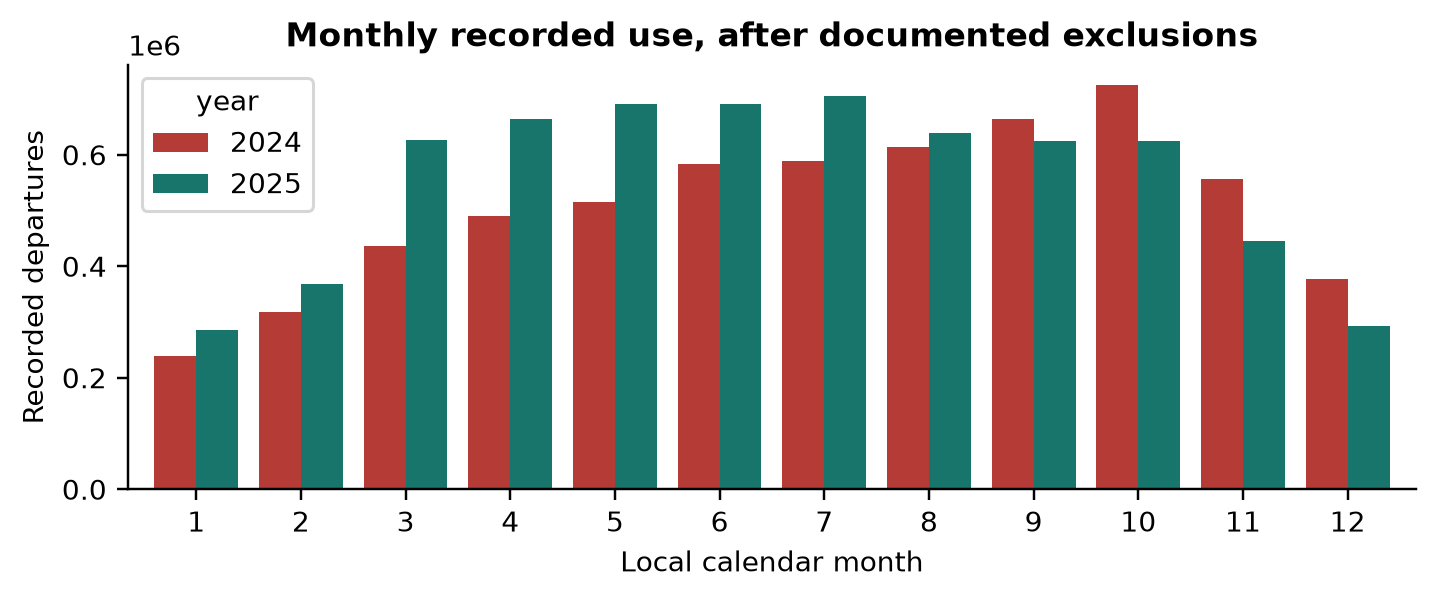

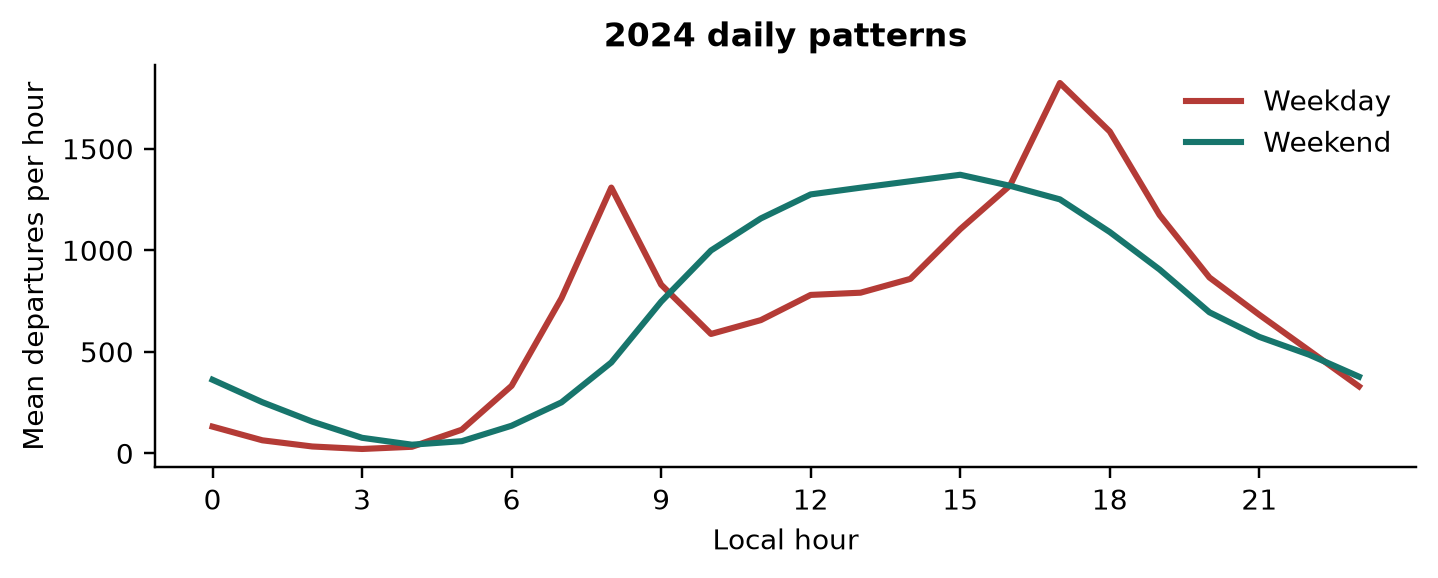

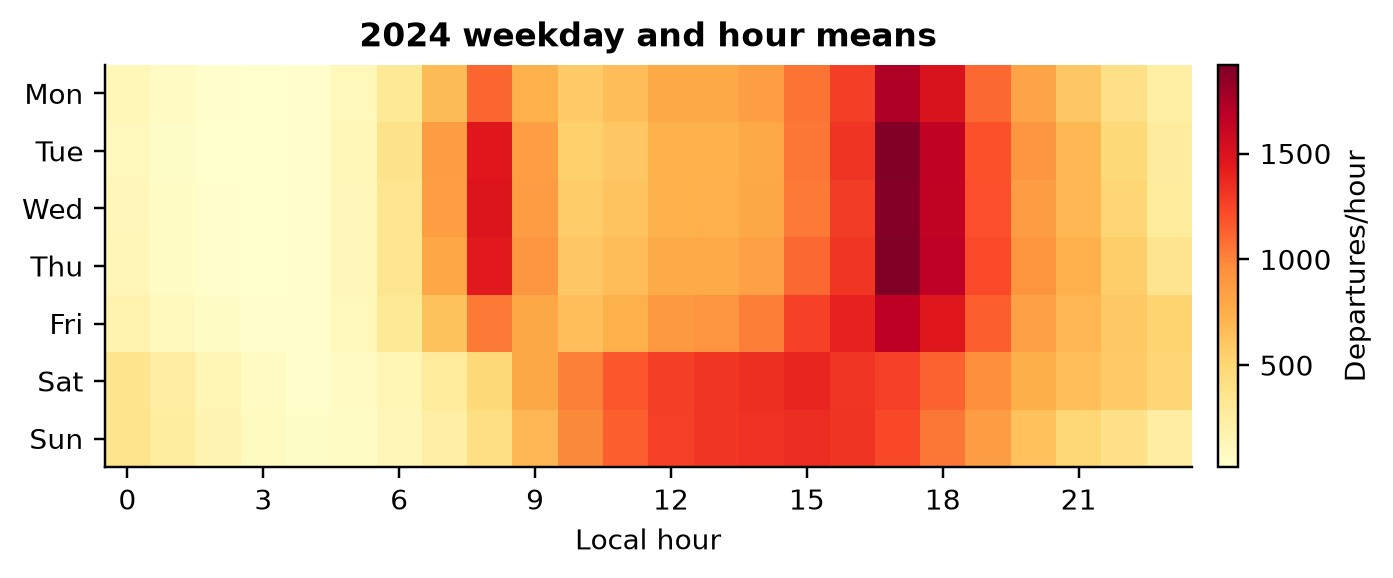

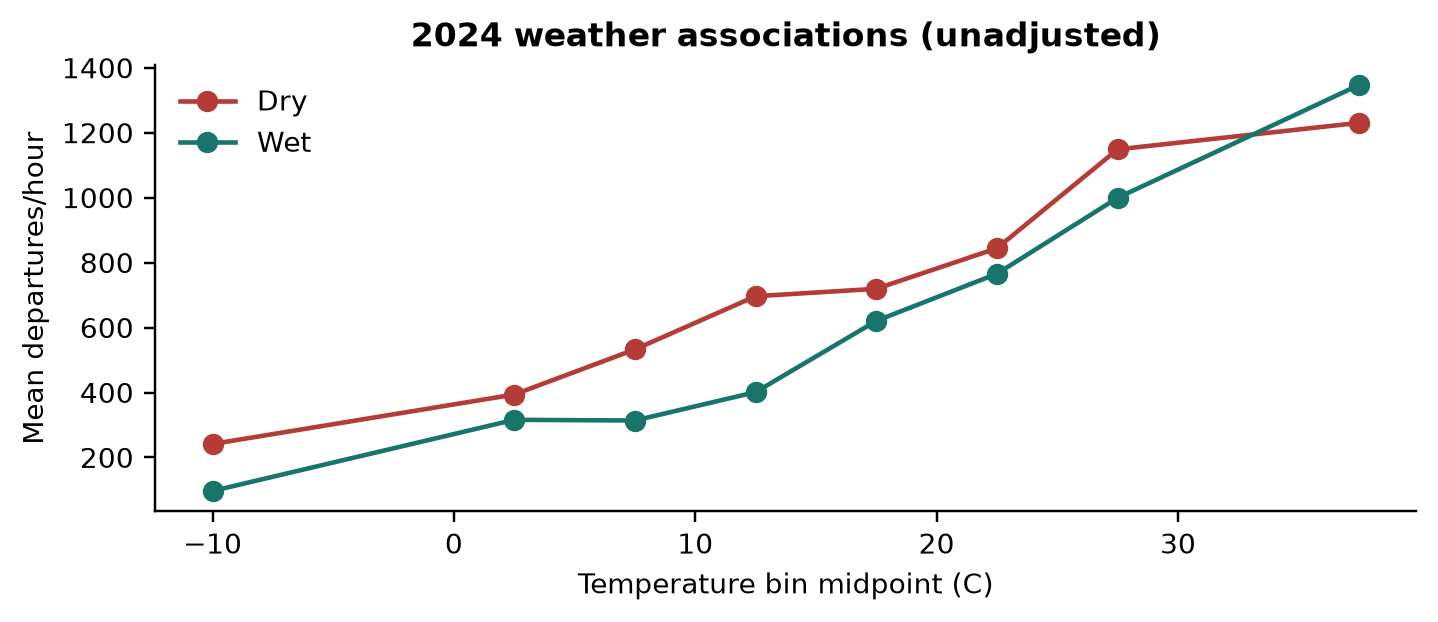

,temp_bin,wet,mean,count
0,"(-20, 0]",Dry,241.377289,546
1,"(-20, 0]",Wet,96.697674,43
2,"(0, 5]",Dry,393.799112,901
3,"(0, 5]",Wet,315.829545,88
4,"(5, 10]",Dry,532.694367,1083
5,"(5, 10]",Wet,313.751825,274
6,"(10, 15]",Dry,696.523717,1033
7,"(10, 15]",Wet,401.106557,244
8,"(15, 20]",Dry,719.404898,1225
9,"(15, 20]",Wet,620.501832,273


In [8]:
for name in ['monthly_counts','hour_profiles','weekday_heatmap','weather_associations']:
    display(Image(filename=str(ROOT / f'results/figures/{name}.png')))
display(pd.read_csv(ROOT / 'results/development_weather_bins.csv'))

## 7. Error analysis
Peak hours are weekdays 07-09 and 16-18 inclusive. Wet means interval precipitation above zero. Temperature groups are below 5 C, 5-25 C and above 25 C. Group sizes are reported because categories overlap and have different use levels. Positive bias means overestimation. The day bootstrap resamples complete days (2,000 resamples, seed 42); its interval is conditional on this test year and does not capture all future distribution shift.

,group,n,mean_rides,MAE,RMSE,R2,bias
0,All,8758,760.679,166.427,241.864,0.855,-67.498
1,Weekday,6264,759.813,167.070,242.973,0.859,-69.965
2,Weekend,2494,762.854,164.811,239.057,0.846,-61.302
3,Peak weekday,1566,1386.344,273.517,350.858,0.720,-140.162
4,Other hours,7192,624.446,143.109,210.788,0.848,-51.676
5,Dry,7400,769.896,161.451,233.920,0.867,-64.512
6,Wet,1358,710.458,193.540,281.237,0.787,-83.766
7,Cold <5C,1978,359.147,102.508,152.156,0.795,-15.707
8,Mild 5-25C,5446,763.102,167.444,240.719,0.846,-56.611
9,Hot >25C,1334,1346.163,257.052,336.400,0.696,-188.733


,month,n,mean_rides,MAE,RMSE,R2,bias
0,1,744.0,384.036,105.044,152.549,0.786,-86.077
1,2,672.0,548.935,147.495,204.482,0.808,-127.105
2,3,743.0,843.432,233.036,333.989,0.767,-222.896
3,4,720.0,922.651,240.722,327.874,0.798,-229.257
4,5,744.0,929.829,244.870,333.378,0.785,-214.640
5,6,720.0,960.440,216.468,287.160,0.822,-199.446
6,7,744.0,948.050,202.974,274.007,0.824,-169.554
7,8,744.0,858.911,78.256,118.178,0.963,-4.195
8,9,720.0,867.993,123.654,177.933,0.927,78.904
9,10,744.0,839.956,124.620,164.057,0.935,106.358


,timestamp_local,rides,prediction,absolute_error,temperature_2m,precipitation
0,2025-03-29 16:00:00-04:00,2930.0,1581.552,1348.448,27.6,0.0
1,2025-03-29 18:00:00-04:00,2693.0,1437.599,1255.401,25.8,0.0
2,2025-07-09 17:00:00-04:00,2580.0,1337.699,1242.301,28.0,5.2
3,2025-03-30 13:00:00-04:00,2612.0,1403.371,1208.629,23.7,0.0
4,2025-03-29 14:00:00-04:00,2800.0,1607.075,1192.925,26.5,0.0
5,2025-03-30 16:00:00-04:00,2539.0,1369.604,1169.396,25.3,0.0
6,2025-03-29 15:00:00-04:00,2791.0,1639.039,1151.961,27.1,0.0
7,2025-05-16 16:00:00-04:00,2344.0,1203.646,1140.354,29.4,5.8
8,2025-03-29 13:00:00-04:00,2670.0,1532.070,1137.930,23.6,0.0
9,2025-03-29 17:00:00-04:00,2683.0,1598.743,1084.257,27.7,0.0


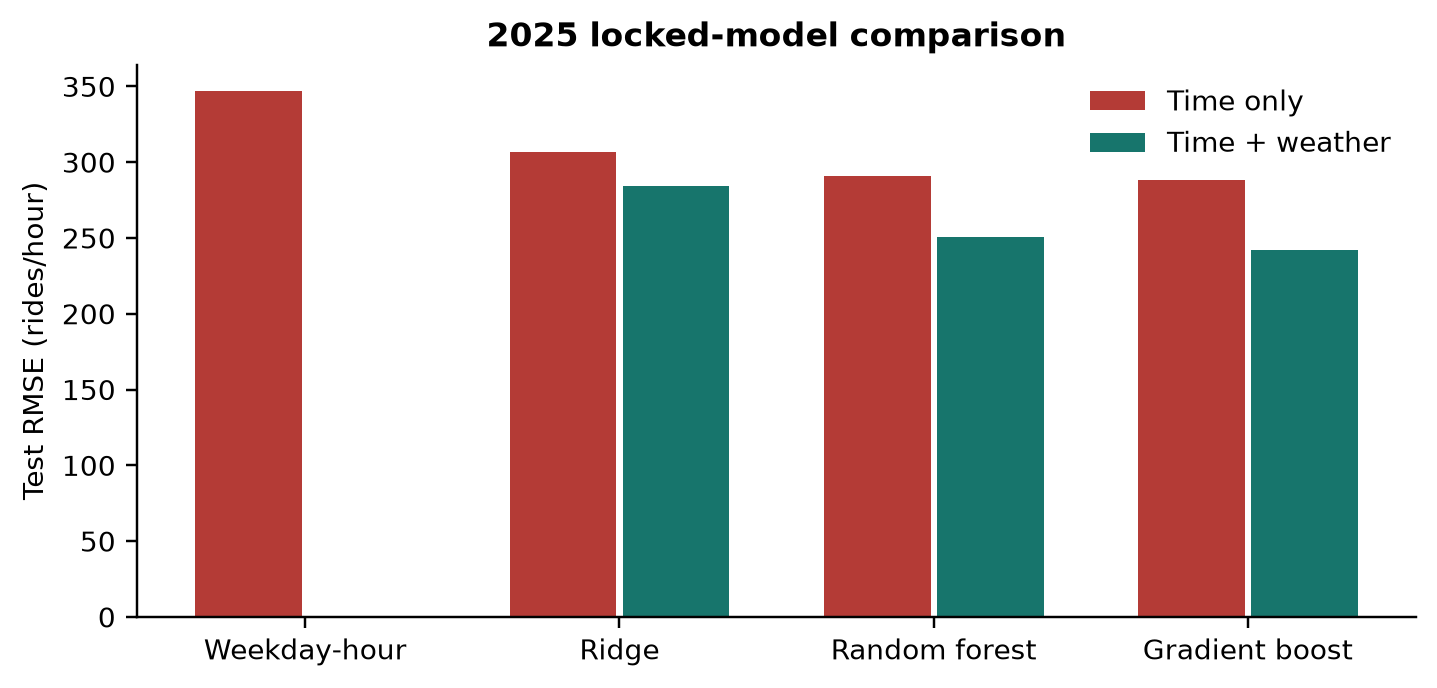

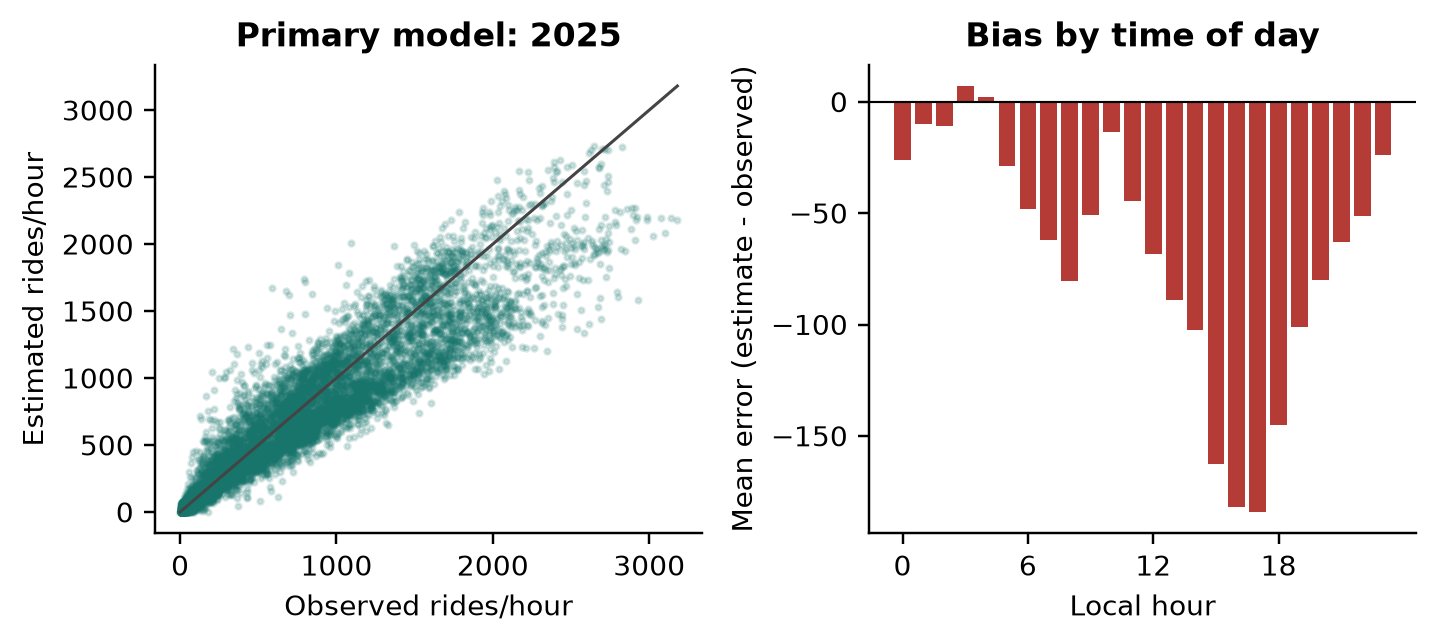

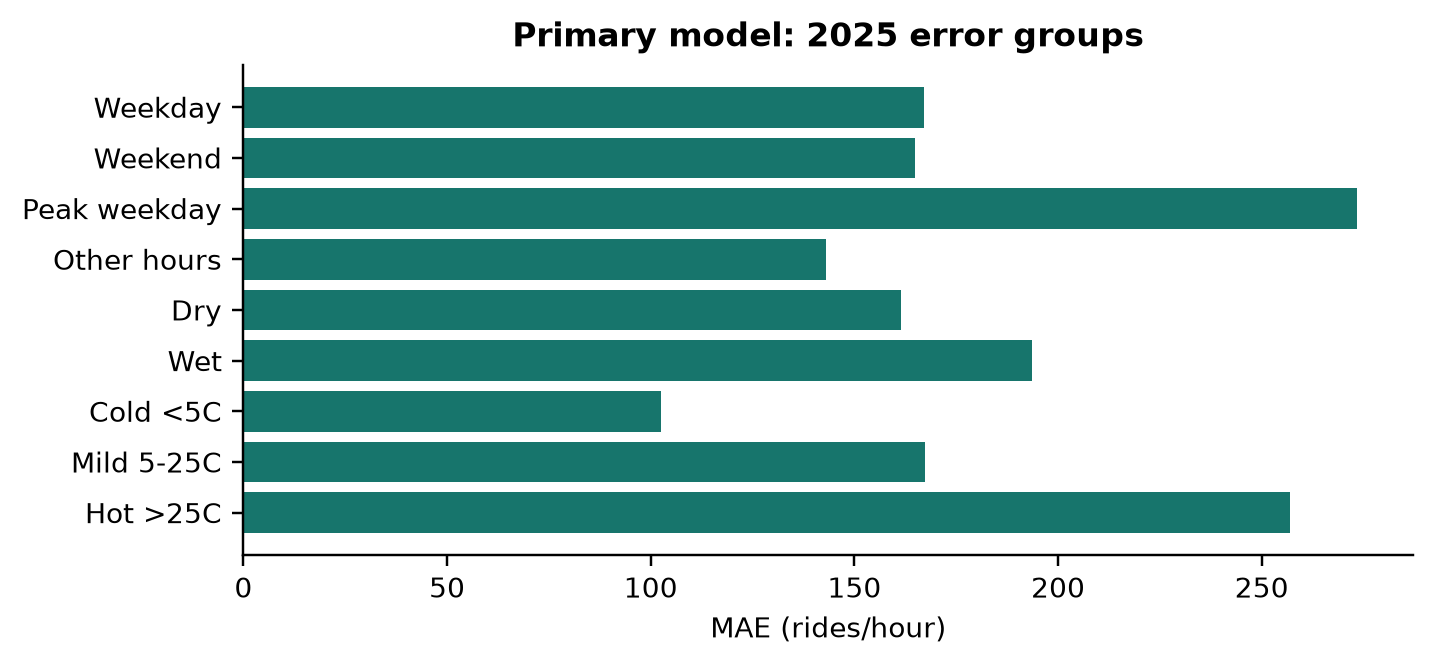

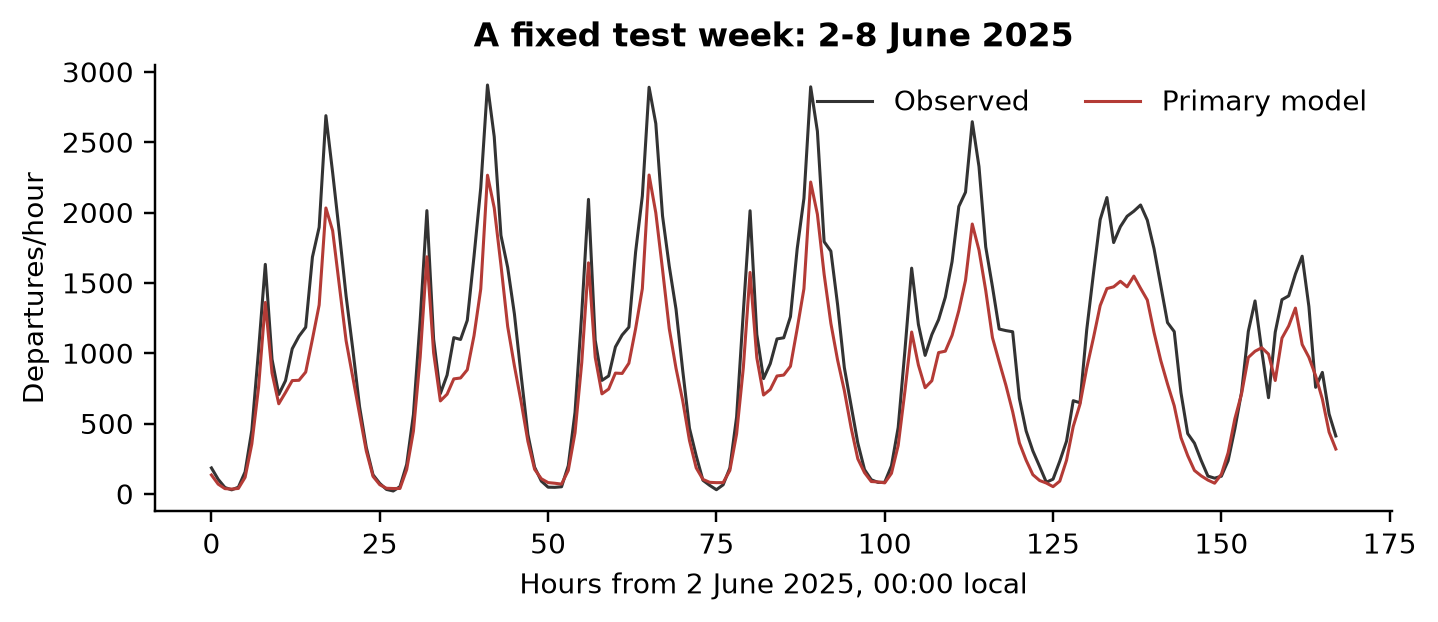

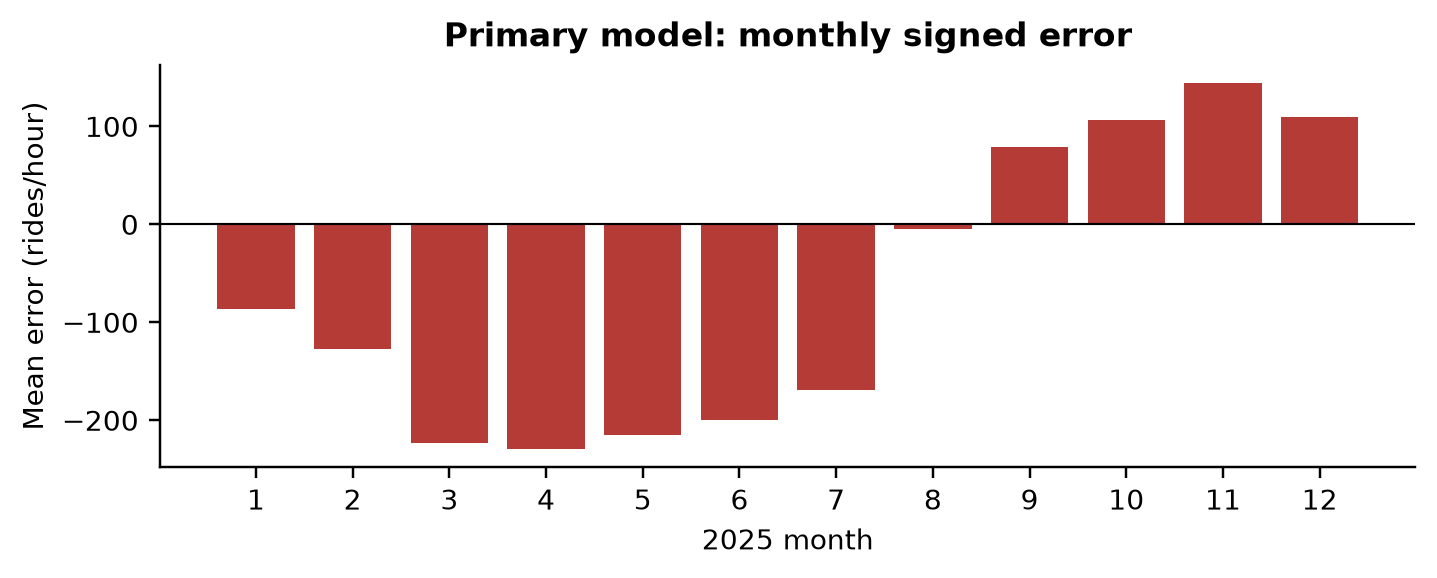

In [9]:
display(pd.read_csv(ROOT / 'results/subgroup_metrics.csv').round(3))
display(pd.read_csv(ROOT / 'results/monthly_test_metrics.csv').round(3))
display(pd.read_csv(ROOT / 'results/largest_errors.csv')[['timestamp_local','rides','prediction','absolute_error','temperature_2m','precipitation']].round(3))
for name in ['test_comparison','error_diagnostics','subgroup_errors','test_week','monthly_bias']:
    display(Image(filename=str(ROOT / f'results/figures/{name}.png')))

## 8. Reproducibility and interpretation checks
The assertion checks below verify metric reproducibility from saved predictions, equal evaluation samples, non-negative predictions, finite features, and the intended split. Read `results/data_audit.json` for all cleaning counts and `results/selection_lock.json` for the 2024 choices.

Limitations: recorded use omits unmet demand; one ERA5 grid point cannot represent every station; same-hour reanalysis is unavailable in advance; system changes and exceptional events can shift the relationship; fall-back target hours are unresolved; trip-file completeness cannot prove the absence of every source outage. Statistical associations do not establish causation.

In [10]:
from experiment import metrics, TIME, WEATHER
prediction_table = pd.read_csv(ROOT / 'results/test_predictions.csv')
score_table = pd.read_csv(ROOT / 'results/test_metrics.csv')
assert len(prediction_table) == summary['n_test']
for row in score_table.to_dict('records'):
    key = row['model'] + '_' + row['features']
    assert prediction_table[key].notna().all() and (prediction_table[key] >= 0).all()
    calculated = metrics(prediction_table.rides, prediction_table[key])
    for metric in ['MAE','RMSE','R2','bias']:
        assert np.isclose(calculated[metric], row[metric], rtol=1e-10, atol=1e-10)
assert not set(TIME + WEATHER) & {'rides','member','casual','ended_at','end_station_id'}
assert hourly.loc[hourly.year == 2024].index.max() < hourly.loc[hourly.year == 2025].index.min()
print('Saved metrics match hourly predictions. All seven models use the same test hours.')
print('No target components or end-of-trip variables are model inputs.')

Saved metrics match hourly predictions. All seven models use the same test hours.
No target components or end-of-trip variables are model inputs.


## Sources
- Capital Bikeshare system data: https://capitalbikeshare.com/system-data
- Official monthly downloads: https://s3.amazonaws.com/capitalbikeshare-data/index.html
- Data license: https://capitalbikeshare.com/data-license-agreement
- Historical weather documentation: https://open-meteo.com/en/docs/historical-weather-api
- Weather data by Open-Meteo.com, ERA5/Copernicus; CC BY 4.0: https://creativecommons.org/licenses/by/4.0/
- Weather data are modified by selecting variables and aligning precipitation to its interval. See `DATA_SOURCES.md` and the report for full references.